# 1D Linear Convection

## Introduction: What is 1D Linear Convection?

The 1D linear convection equation is a first-order partial differential equation (PDE). It models the advection (transport) of a scalar quantity (for example a velocity component, a temperature, or a concentration) in a single spatial dimension as time progresses. It describes how a physical property (like a wave) travels through space at a constant speed without changing its shape.

$$ \frac{\partial u}{\partial t} + c\frac{\partial u}{\partial x} = 0 $$
where $c$ is the constant wave speed.

## Why do we use it?

It captures the basic physics of how information travels through a medium. It is the simplest model for learning how to discretize PDEs and understand numerical stability. It helps researchers test new numerical schemes (like upwind or Lax-Wendroff) before applying them to the full Navier-Stokes equations.

## Where does the equation come from?

This equation is a simplified version of the **Navier-Stokes equations**, which govern fluid flow. To get the 1D linear convection form, we take the full momentum equation and assume the following:

1. Only one spatial dimension ($x$).
2. Neglect viscosity/diffusion ($\mu = 0$).
3. Neglect pressure gradients ($\nabla p = 0$).
4. Replace the convecting velocity by a constant propagation speed $c$ (linearization).

Assumptions 1-3 give the nonlinear convection equation $\partial u/\partial t + u\,\partial u/\partial x = 0$; assumption 4 turns it into the linear equation above.

## Derivation from the Substantial Derivative

We can also derive the 1D linear convection equation from the **substantial derivative**.

#### What is the substantial (material) derivative?

The **material derivative** (also called the substantial or Lagrangian derivative) describes the rate of change of a property, such as temperature or velocity, of a specific fluid element (parcel) as it moves through space and time.

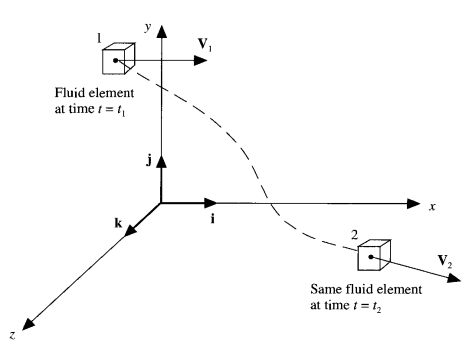

The figure above shows a fluid element moving in a flow field. It illustrates the substantial derivative.

To derive the material derivative using a **Taylor series** expansion, we look at how a property $\phi$ changes for a fluid element moving from position $\mathbf{r}$ at time $t$ to a new position $\mathbf{r} + \Delta\mathbf{r}$ at time $t + \Delta t$.

Consider a fluid property $\phi(\mathbf{r},t)$. A fluid element moves from $(x,y,z,t)$ to $(x+\Delta x,\,y+\Delta y,\,z+\Delta z,\,t+\Delta t)$ in a small time interval $\Delta t$.

The change in the property, $\Delta\phi$, is:

$$ \Delta\phi = \phi(t+\Delta t,x+\Delta x,y+\Delta y,z+\Delta z) - \phi(t,x,y,z) $$

#### Expand using a Taylor series

Expanding $\phi(t+\Delta t,x+\Delta x,y+\Delta y,z+\Delta z)$ around the point $(t,x,y,z)$ and keeping only the first-order terms:

$$\phi(t+\Delta t,x+\Delta x,y+\Delta y,z+\Delta z) \approx \phi(t,x,y,z) + \frac{\partial \phi}{\partial t}\Delta t + \frac{\partial \phi}{\partial x}\Delta x + \frac{\partial \phi}{\partial y}\Delta y + \frac{\partial \phi}{\partial z}\Delta z $$

#### Substitute into the change equation

$$\Delta\phi \approx \frac{\partial\phi}{\partial t}\Delta t + \frac{\partial\phi}{\partial x}\Delta x + \frac{\partial\phi}{\partial y}\Delta y + \frac{\partial\phi}{\partial z}\Delta z $$

#### Divide by $\Delta t$

To find the rate of change, we divide the entire expression by $\Delta t$:

$$ \frac{\Delta \phi}{\Delta t} \approx \frac{\partial \phi}{\partial t} + \frac{\partial \phi}{\partial x}\frac{\Delta x}{\Delta t} + \frac{\partial \phi}{\partial y}\frac{\Delta y}{\Delta t} +\frac{\partial \phi}{\partial z}\frac{\Delta z}{\Delta t} $$

#### Take the limit as $\Delta t \to 0$

In the limit, the ratios $\frac{\Delta x}{\Delta t}, \frac{\Delta y}{\Delta t}, \frac{\Delta z}{\Delta t}$ become the velocity components $u, v, w$ of the fluid element, and the approximation becomes exact:

$$ \frac{D\phi}{Dt} = \frac{\partial\phi}{\partial t} + u\frac{\partial\phi}{\partial x} + v\frac{\partial\phi}{\partial y} + w\frac{\partial\phi}{\partial z} $$

#### Vector notation

Using the gradient operator $\nabla$ and the velocity vector $\vec{v}$:

$$ \frac{D\phi}{Dt} = \frac{\partial\phi}{\partial t} + (\vec{v}\cdot \nabla)\phi $$

#### The physical meaning of the substantial derivative

1. $\frac{D\phi}{Dt}$ is the **material derivative** (total change): the total change of the property as the fluid element moves in space and time.

2. $\frac{\partial \phi}{\partial t}$ is the **local change** (local derivative): how the property changes at a fixed point. It shows the transient fluctuations at that point.

3. $(\vec{v}\cdot \nabla)\phi$ is the **convective change** (convective term): how the property changes because the fluid element moves to a new location where conditions are different. It shows the change due to moving through a spatial gradient.

#### Relate the material derivative to the 1D linear convection equation

In this section the transported quantity is called $u$ (it plays the role of $\phi$). Its material derivative is defined as:
$$\frac{Du}{Dt} = \frac{\partial u}{\partial t} + \vec{v}\cdot\nabla u $$

For a 1D case where the convecting velocity is a constant $c$, this becomes:
$$ \frac{Du}{Dt} = \frac{\partial u}{\partial t} + c \frac{\partial u}{\partial x} $$

The convection equation describes a scenario where the property carried by a fluid particle does **not change** as the particle moves ($\frac{Du}{Dt} = 0$). Setting the material derivative to zero gives the standard convection equation:

$$ \frac{\partial u}{\partial t} + c \frac{\partial u}{\partial x} = 0 $$

## The Exact Solution for 1D Linear Convection

We can find the exact solution of the 1D linear convection equation because the equation describes a very simple physical process: **pure translation**. Because the wave speed $c$ is constant and there are no other effects (like diffusion or pressure) to change the shape of the wave, the initial condition simply "slides" across the domain.

Mathematically, this is possible for two main reasons:

#### 1. The method of characteristics

The 1D linear convection equation belongs to a class of equations called **hyperbolic PDEs**. For these equations, information travels along lines in the space-time plane called **characteristics**.

* Along these lines ($x - ct = \text{constant}$), the value of $u$ remains exactly the same as its initial value.

* This allows us to "trace" any point back to the starting time ($t = 0$) to find its value.

#### 2. Transformation to a simple ODE

By changing the coordinate system from $(x,t)$ to a moving coordinate $X = x-ct$, the PDE turns into a trivial equation, $\partial U/\partial t = 0$, where $U(X,t) = u(x,t)$:
$$ \frac{\partial U}{\partial t} = 0 $$

This simply says that, in the moving frame, the value does not change over time.

#### The exact solution

The initial shape is $u(x,0) = u_0(x)$. Recall the material (substantial) derivative equation:
$$ \frac{Du}{Dt} = \frac{\partial u}{\partial t} + c \frac{\partial u}{\partial x} = 0 $$

Since $\frac{Du}{Dt} = 0$, $u$ is constant along the path. Then, $u(x,t) = u_0(x_0)$, where $x_0$ is the starting position of the path.

To determine $x_0$: along a characteristic the position changes at the constant speed, $\frac{dx}{dt} = c$, so
$$dx = c\,dt$$

By integrating both sides:

$$ \int_{x_0}^{x}dx = \int_{0}^{t}c\,dt $$

$$ x_0 = x-ct $$

Therefore, the exact solution at any future time $t$ is always:
$$ u(x,t) = u_0(x-ct) $$

This means the shape at time $t$ is exactly the same as the initial shape, just shifted to the right by a distance of $ct$.  
The figure below illustrates this.

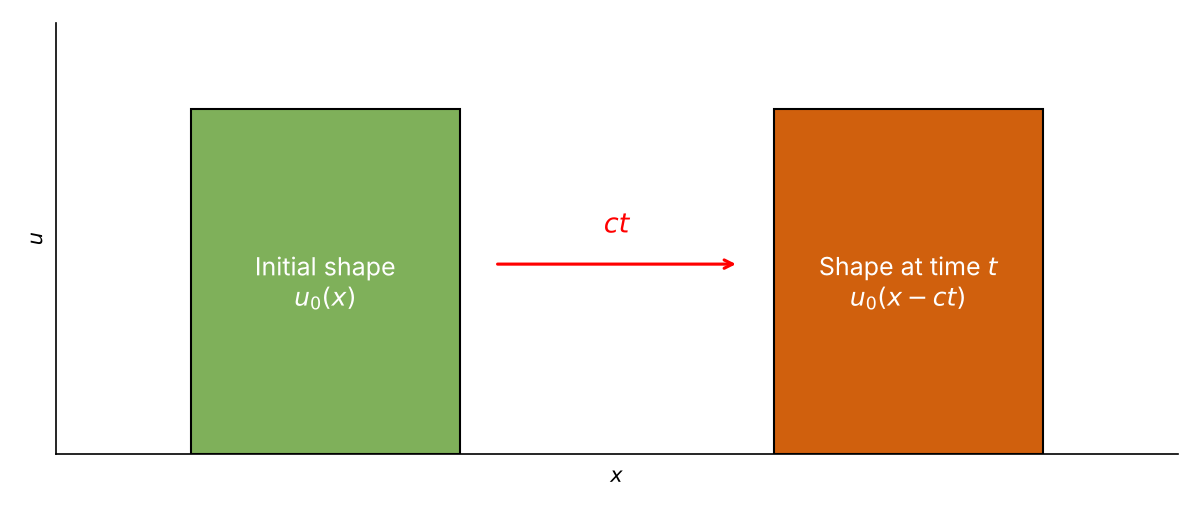

## Numerical Solution for 1D Linear Convection

We discretize the 1D linear convection equation in both space and time, using the forward difference scheme for the time derivative and the backward difference scheme for the space derivative.

**Why do we choose the forward difference for the time derivative and the backward difference for the space derivative (the FTBS explicit scheme)?**

**Forward difference (time)** is chosen for its **simplicity**: it makes the scheme **explicit**. It lets us calculate the future state $(n+1)$ using only known values from the current state $(n)$.

**Backward difference (space)** is chosen for its **stability**: it follows the **upwind principle**. Since the wave (the information) moves to the right ($c>0$), the value at any point depends on what is happening behind it (to its left). Looking "backward" captures this incoming information.  
If we looked "forward" in space instead, the scheme would ignore the incoming wave and the simulation would be unstable.

#### Using the FTBS explicit scheme for 1D linear convection

Consider discretizing the spatial coordinate $x$ into points that we index from $i = 0$ to $N$, and stepping in discrete time intervals of size $\Delta t$.

For the **forward difference (time)**, the derivative can be approximated as:
$$ \frac{\partial u}{\partial t} \approx \frac{u(t+\Delta t,x)-u(t,x)}{\Delta t} = \frac{u_i^{n+1} - u_{i}^n}{\Delta t} $$

For the **backward difference (space)**, the derivative can be approximated as:
$$ \frac{\partial u}{\partial x}\approx \frac{u(t,x)-u(t,x-\Delta x)}{\Delta x} = \frac{u_i^n-u_{i-1}^n}{\Delta x} $$

The discretized 1D linear convection equation becomes:
$$ \frac{u_i^{n+1}-u_i^n}{\Delta t} + c\frac{u_i^n - u_{i-1}^n}{\Delta x} = 0 $$

Here $n$ and $n+1$ are two consecutive steps in time, while $i-1$ and $i$ are two neighboring points of the discretized $x$ coordinate. If the initial conditions are given, then the only unknown in this discretization is $u_i^{n+1}$. We can solve for it to get an equation that allows us to advance in time:

$$ u_i^{n+1} = u_i^n - c\frac{\Delta t}{\Delta x}(u_i^n-u_{i-1}^n) $$

In the above equation we have a special term, $\frac{\Delta t}{\Delta x}$. What does this term represent?

In the context of the 1D linear convection equation, the term $\frac{\Delta t}{\Delta x}$ is called the **grid ratio** or **mesh ratio**.

When multiplied by the wave speed $c$, it forms the **CFL number** (Courant-Friedrichs-Lewy number), which is the most critical parameter in our simulation:

$$ \sigma = c\frac{\Delta t}{\Delta x} $$

**What it means**

1. **Physical meaning**: it represents how far the wave travels ($c\Delta t$) compared to the size of one grid cell ($\Delta x$).

2. **Stability (the CFL condition)**: for an explicit scheme like FTBS to work, this ratio must be small enough that $\sigma \le 1$.
   1. **If $\sigma \le 1$**: the wave travels no more than one cell per time step, and the simulation is **stable**.
   2. **If $\sigma > 1$**: the wave "skips" over cells faster than the scheme can follow it, because the scheme only uses information from the neighboring cell. The simulation becomes **unstable** (numerical instability).

So this ratio sets our **time step limit**. If we make our grid finer (smaller $\Delta x$), we must also make our time step $\Delta t$ smaller to keep the simulation stable.

## Numerical Simulation of 1D Linear Convection using Python

Now let's implement the discretized equation in Python.

**We are using a conservative discretization scheme. Why?**  
The conservative form of a transport equation says that the rate of change of a quantity inside a cell equals the net flux through the cell faces (a fixed control volume). The FTBS update can be written in exactly this form, using the upwind numerical flux $F_{i+1/2}^n = c\,u_i^n$ (for $c>0$):

$$ u_i^{n+1} = u_i^n - \frac{\Delta t}{\Delta x}\left(F_{i+1/2}^n - F_{i-1/2}^n\right) = u_i^n - c\frac{\Delta t}{\Delta x}\left(u_i^n - u_{i-1}^n\right) $$

The flux leaving cell $i$ is exactly the flux entering cell $i+1$, so when the update is summed over all cells the interior terms cancel. The total amount of the transported quantity, i.e. the area under the curve $\sum_i u_i\,\Delta x$, can then change only through the boundaries. While the wave stays away from the boundaries, the total area is therefore preserved.

Note that this is a statement about the **total**, not about the **shape**: the first-order upwind scheme still smears sharp edges (numerical diffusion, discussed after the results below).

Now let us write the scheme in Python.

In [1]:
import os
import numpy as np                      # NumPy: arrays and array operations
from matplotlib import pyplot           # pyplot module of Matplotlib: 2D plotting

# make Matplotlib plots appear inside the notebook (instead of in a separate window)
%matplotlib inline

First, we need to assign variables for the **spatial domain**. We want to define an evenly spaced grid of points within a spatial domain that is 2 units of length wide, i.e., $x_i\in [0,2]$. We'll define a variable `nx`, which will be the number of grid points we want, and `dx`, which will be the distance between any pair of adjacent grid points.

In [2]:
nx = 61                # try changing this number from 41 to 81 and Run All... What happens?
dx = 2 / (nx - 1)      # grid spacing, Delta x
dx

0.03333333333333333

Second, we need to assign variables for the **temporal resolution**. The total number of "snapshots" or iterations the simulation will run (the number of time steps) is assigned to `nt`. The amount of time that passes between each iteration (the time step size, $\Delta t$) is assigned to `dt`. And the constant speed at which the quantity (the wave) moves across the grid (the propagation speed) is assigned to `c`.

In [3]:
nt = 20
dt = 0.025             # from nt and dt the total time is 20 * 0.025 = 0.5 s
c = 1                  # wave speed of 1 m/s: the wave travels exactly 0.5 m during the 0.5 s simulation

# CFL number (stability condition): sigma = c*dt/dx must be <= 1.
# If it is larger, the scheme becomes unstable and the solution blows up.
sigma = c * dt / dx
print(f"CFL number sigma = {sigma:.2f}")

CFL number sigma = 0.75


We also need to set up our initial conditions. The initial velocity $u_0$ is given as $u=2$ in the interval $0.5\le x \le 1$ and $u = 1$ everywhere else in $[0,2]$ (i.e., a hat function).

So, let us create an array for these initial condition values. We can use the NumPy function `ones()`, which defines an array that is `nx` elements long with every value equal to 1.

In [4]:
u = np.ones(nx)          # ones() from the NumPy library

# Set u = 2 between x = 0.5 and x = 1, as required by the initial condition.
# To do that we need the indices of x = 0.5 and x = 1 in the spatial grid.
# x = 0.5 is at index 0.5/dx, and x = 1 is at index 1/dx.
# In Python the last index of a slice is excluded, so we add 1 to include x = 1.
# Therefore the final slice is [int(0.5/dx) : int(1/dx + 1)].
u[int(0.5 / dx): int(1 / dx + 1)] = 2
print(u)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Now let's take a look at the initial conditions using a Matplotlib plot. We've imported the `pyplot` module from the `matplotlib` library, and we'll use its plotting function `plot`, so we call `pyplot.plot`.

Here we use the syntax for a simple 2D plot, `plot(x, y)`, where the `x` values are the evenly distributed grid points:

In [5]:
x = np.linspace(0, 2, nx)    # evenly distributed grid points from 0 to 2 (nx points)

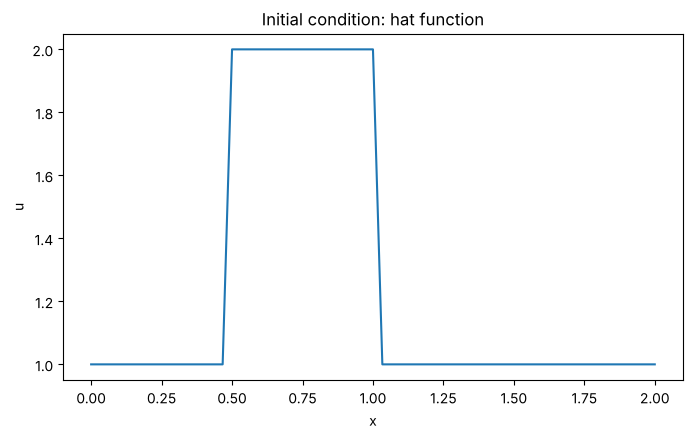

In [6]:
pyplot.figure(figsize=(8, 4.5))
pyplot.plot(x, u)
pyplot.xlabel("x")
pyplot.ylabel("u")
pyplot.title("Initial condition: hat function")
os.makedirs("figures", exist_ok=True)
pyplot.savefig("figures/initial_condition.png", dpi=150, bbox_inches="tight")
pyplot.show()

Finally, we advance the solution in time with the FTBS update, compute the exact solution $u_0(x-ct)$, and measure the error and the total area.

In [7]:
u0 = u.copy()                                   # keep the initial condition

# FTBS time stepping: u[0] stays at 1 (inflow boundary)
for n in range(nt):
    un = u.copy()                               # solution at the old time level n
    for i in range(1, nx):
        u[i] = un[i] - c * dt / dx * (un[i] - un[i - 1])

# exact solution at t = nt*dt: the initial hat shifted to the right by c*t
xs = x - c * nt * dt
u_exact = np.where((xs >= 0.5) & (xs <= 1.0), 2.0, 1.0)

# diagnostics: L1 error and total area, computed as dx * sum(u)
l1_error = dx * np.sum(np.abs(u - u_exact))
print(f"L1 error (FTBS vs exact): {l1_error:.3f}")
print(f"Area, initial: {dx * np.sum(u0):.3f}")
print(f"Area, FTBS:    {dx * np.sum(u):.3f}")
print(f"Area, exact:   {dx * np.sum(u_exact):.3f}")

L1 error (FTBS vs exact): 0.101
Area, initial: 2.567
Area, FTBS:    2.567
Area, exact:   2.567


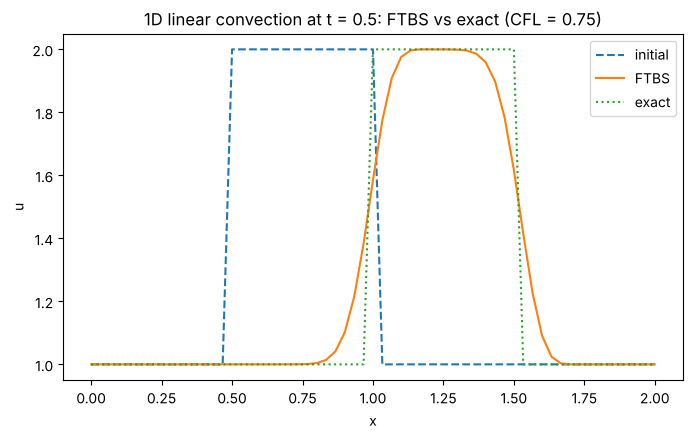

In [8]:
pyplot.figure(figsize=(8, 4.5))
pyplot.plot(x, u0, "--", label="initial")
pyplot.plot(x, u, label="FTBS")
pyplot.plot(x, u_exact, ":", label="exact")
pyplot.xlabel("x")
pyplot.ylabel("u")
pyplot.title(f"1D linear convection at t = {nt * dt:.1f}: FTBS vs exact (CFL = {sigma:.2f})")
pyplot.legend()
pyplot.savefig("figures/ftbs_vs_exact.png", dpi=150, bbox_inches="tight")
pyplot.show()

#### Reading the result

The FTBS hat is in the right position (shifted by $ct = 0.5$) and has roughly the right height, but its sharp edges are **smeared**, while the exact hat keeps vertical edges. This smearing is **numerical diffusion**, the well-known weakness of a first-order upwind scheme. It can be explained with the modified equation: FTBS does not solve the pure convection equation exactly, it behaves like

$$ \frac{\partial u}{\partial t} + c\frac{\partial u}{\partial x} = \frac{c\,\Delta x}{2}\,(1-\sigma)\,\frac{\partial^2 u}{\partial x^2} + O(\Delta x^2), $$

i.e. convection plus an artificial diffusion term with numerical viscosity $\frac{c\,\Delta x}{2}(1-\sigma)$. For $\sigma = 0.75$ this is about $0.004$. The smearing becomes weaker on a finer grid and vanishes at $\sigma = 1$, where FTBS reproduces the exact shift of one cell per time step.

The **total area** under the curve is the same for the initial, FTBS and exact solutions (see the printed values above). This is the conservation property discussed earlier: the scheme preserves the total, but not the shape.

#### Suggested experiments

* `nx = 41` gives $\sigma = 0.5$: the solution is more smeared and the L1 error is larger.
* `nx = 81` gives $\sigma = 1$: FTBS reproduces the exact solution on the grid (zero error).
* `nx = 101` gives $\sigma = 1.25 > 1$: the scheme is unstable and the solution blows up.